# Démonstration de `MonACP`

Ce notebook présente l'utilisation de la classe `MonACP` du module `ml_tools.pca`.

Objectif : montrer, de façon visuelle et progressive, comment :

- préparer un petit jeu de données ;
- entraîner une ACP normée ;
- lire le bilan des valeurs propres ;
- interpréter le cercle des corrélations ;
- projeter un nouvel individu ;
- comparer les méthodes `normed`, `non_normed` et `spearman`.

Le jeu de données est synthétique : il est généré avec une graine fixe, donc les résultats sont reproductibles et aucun téléchargement n'est nécessaire.


In [1]:
import sys
from pathlib import Path

# Permet d'importer ml_tools que le notebook soit exécuté depuis la racine
# du projet ou depuis le dossier notebooks/.
RACINE = Path.cwd()
while not (RACINE / "ml_tools").exists() and RACINE != RACINE.parent:
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ml_tools.pca import MonACP

pd.set_option("display.float_format", lambda x: f"{x:.2f}")


## 1. Un petit jeu de données synthétique

Nous simulons **40 clients** décrits par **6 variables** :

- `age` : âge du client ;
- `revenu` : revenu annuel (en k€) ;
- `anciennete` : ancienneté dans la relation client (en années) ;
- `nb_achats` : nombre d'achats par an ;
- `panier_moyen` : montant moyen d'un panier (en €) ;
- `satisfaction` : note de satisfaction sur 10.

Les variables sont volontairement corrélées pour que l'ACP ait quelque chose à raconter.


In [2]:
rng = np.random.default_rng(42)
n = 40

age = rng.integers(22, 61, n).astype(float)
revenu = 12 + 0.9 * age + rng.normal(0, 8, n)
anciennete = np.clip(0.1 * age + rng.normal(0, 2, n), 0, None)
nb_achats = np.clip(
    2 + 0.08 * revenu + 0.7 * anciennete + rng.normal(0, 3, n), 0, None
)
panier_moyen = 25 + 0.9 * revenu + 2.0 * nb_achats + rng.normal(0, 15, n)
satisfaction = np.clip(
    5 + 0.04 * revenu + 0.15 * anciennete + rng.normal(0, 1.2, n), 1, 10
)

df = pd.DataFrame(
    {
        "age": age,
        "revenu": revenu,
        "anciennete": anciennete,
        "nb_achats": nb_achats,
        "panier_moyen": panier_moyen,
        "satisfaction": satisfaction,
    },
    index=[f"Client_{i:02d}" for i in range(1, n + 1)],
)

display(df.round(1).head())
display(df.describe().round(2))


,age,revenu,anciennete,nb_achats,panier_moyen,satisfaction
Client_01,25.00,33.00,0.00,3.50,67.90,7.90
Client_02,52.00,53.40,4.50,13.30,84.80,8.10
Client_03,47.00,64.10,5.00,9.60,69.80,7.80
Client_04,39.00,45.90,5.10,11.40,93.20,8.90
Client_05,38.00,42.80,5.20,6.30,63.90,8.00


,age,revenu,anciennete,nb_achats,panier_moyen,satisfaction
count,40.00,40.00,40.00,40.00,40.00,40.00
mean,42.22,50.92,3.81,8.79,86.22,7.66
std,10.85,12.00,1.71,3.74,19.94,1.21
min,24.00,22.84,0.00,1.23,52.51,5.35
25%,35.00,43.73,2.78,6.60,69.84,6.88
50%,42.50,52.60,3.85,8.47,84.90,7.51
75%,52.00,59.41,5.10,11.11,100.43,8.37
max,60.00,72.56,7.09,17.59,133.46,10.00


## 2. ACP normée

On centre et réduit chaque variable, puis on diagonalise la matrice de corrélation.

Le paramètre `method="normed"` correspond à l'ACP la plus classique (Pearson).


In [3]:
acp = MonACP(method="normed").fit(df)
acp.bilan()



================ BILAN DE L'ACP (NORMED) ================
Variables actives (6) : ['age', 'revenu', 'anciennete', 'nb_achats', 'panier_moyen', 'satisfaction']
Critère de Kaiser (Val. Propre > 1.00) -> Conserver 2 axe(s).
------------------------------------------------------------
Axe      | Val. Propre  | % Info     | % Cumulé   | Kaiser ?
------------------------------------------------------------
Axe 1    | 3.3400       | 55.67    % | 55.67    % | OUI
Axe 2    | 1.0446       | 17.41    % | 73.08    % | OUI
Axe 3    | 0.6720       | 11.20    % | 84.28    % | NON
Axe 4    | 0.5508       | 9.18     % | 93.46    % | NON
Axe 5    | 0.2897       | 4.83     % | 98.28    % | NON
Axe 6    | 0.1030       | 1.72     % | 100.00   % | NON
------------------------------------------------------------


## 3. La matrice de corrélation

La matrice de corrélation permet de voir rapidement quelles variables évoluent ensemble.

- Une valeur proche de `1` indique une corrélation positive forte.
- Une valeur proche de `-1` indique une corrélation négative forte.
- Une valeur proche de `0` indique peu de relation linéaire.


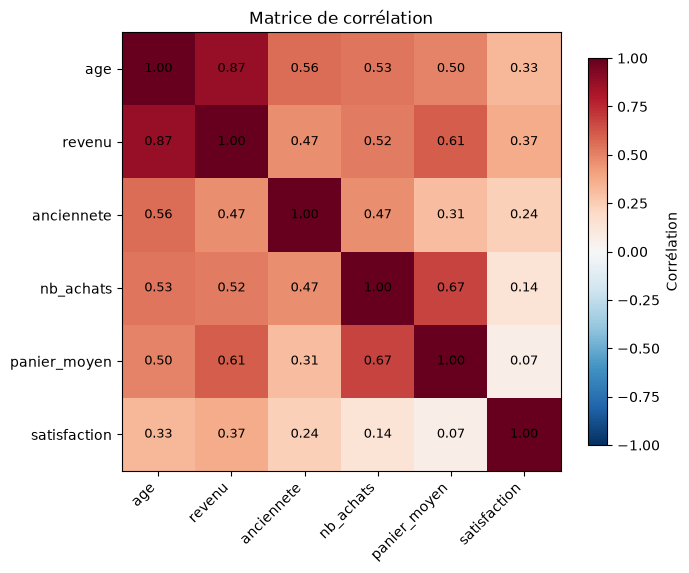

In [4]:
matrice = acp.matrix_

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(matrice, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(matrice.columns)))
ax.set_xticklabels(matrice.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matrice.index)))
ax.set_yticklabels(matrice.index)

for i in range(len(matrice)):
    for j in range(len(matrice)):
        ax.text(
            j,
            i,
            f"{matrice.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9,
        )

fig.colorbar(image, ax=ax, shrink=0.8, label="Corrélation")
ax.set_title("Matrice de corrélation")
plt.tight_layout()
plt.show()


## 4. Coordonnées des variables et des individus

Deux méthodes sont utilisées :

- `get_coord_variables(n_axes=2)` donne les coordonnées des **variables** ;
- `transform(df, n_axes=2)` projette les **individus** sur les axes.


In [5]:
df_variables = acp.get_coord_variables(n_axes=2)
df_individus = acp.transform(df, n_axes=2)

display(df_variables.round(2))
display(df_individus.round(2))


,Axe_1,Axe_2
age,-0.88,-0.14
revenu,-0.89,-0.11
anciennete,-0.68,-0.13
nb_achats,-0.77,0.37
panier_moyen,-0.74,0.47
satisfaction,-0.40,-0.80


,Axe_1,Axe_2
Client_01,3.29,-0.42
Client_02,-1.27,-0.06
Client_03,-0.81,-0.68
Client_04,-0.60,-0.42
Client_05,0.90,-0.97
Client_06,-2.46,-1.62
Client_07,3.02,-0.29
Client_08,-0.57,0.73
Client_09,0.62,2.02
Client_10,2.78,-1.53


## 5. Les graphiques de l'ACP

La méthode `tracer_acp` renvoie une figure contenant :

- à gauche, la carte des individus ;
- à droite, le cercle des corrélations des variables.


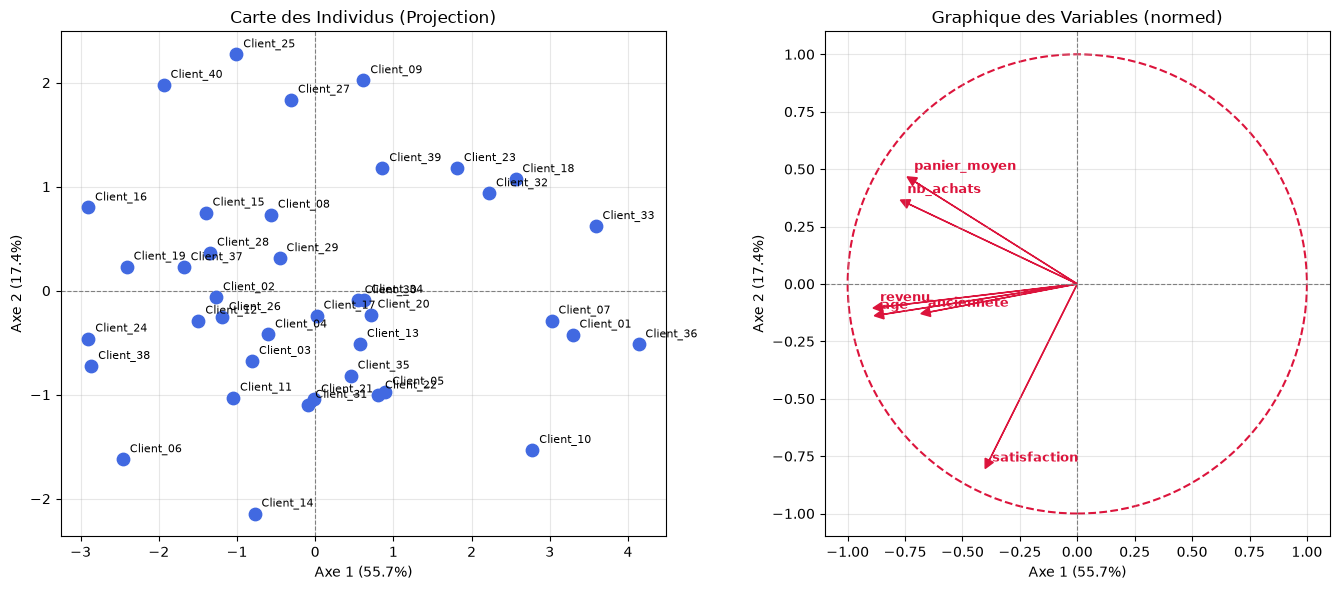

In [6]:
fig = acp.tracer_acp(df_individus, df_variables)
plt.show()


### Comment lire le cercle des corrélations ?

- Une variable proche du cercle unité est bien représentée par les deux axes.
- Deux flèches proches indiquent des variables corrélées positivement.
- Deux flèches opposées indiquent une corrélation négative.
- Deux flèches perpendiculaires indiquent peu de corrélation linéaire.
- Plus une variable est proche du centre, moins elle est bien représentée.

La qualité de représentation d'une variable sur les deux axes est la somme des carrés de ses coordonnées.

Ici, les étiquettes de `age`, `revenu` et `anciennete` se superposent : ces variables pointent presque dans la même direction, donc elles sont fortement corrélées. De même, certaines étiquettes de clients se chevauchent lorsque leurs profils sont proches.


In [7]:
qualite = (df_variables**2).sum(axis=1).rename("qualité (cos²)")
display(qualite.round(3).to_frame())


,qualité (cos²)
age,0.80
revenu,0.80
anciennete,0.48
nb_achats,0.73
panier_moyen,0.77
satisfaction,0.81


## 6. Projeter un nouvel individu

Une fois l'ACP entraînée, on peut projeter un nouveau client sans recalculer les axes.

Les paramètres de centrage et de réduction appris pendant le `fit()` sont réutilisés.


In [8]:
nouveau_client = pd.DataFrame(
    {
        "age": [35.0],
        "revenu": [45.0],
        "anciennete": [4.0],
        "nb_achats": [12.0],
        "panier_moyen": [85.0],
        "satisfaction": [7.5],
    },
    index=["Client_41"],
)

display(acp.transform(nouveau_client, n_axes=2).round(2))


,Axe_1,Axe_2
Client_41,0.22,0.52


## 7. Comparer les trois méthodes

- `normed` : ACP sur la matrice de corrélation (variables centrées-réduites).
- `non_normed` : ACP sur la matrice de covariance (échelles d'origine).
- `spearman` : ACP sur les rangs, plus robuste aux valeurs extrêmes.

Les pourcentages d'inertie peuvent changer selon la méthode.


In [9]:
for methode in ("normed", "non_normed", "spearman"):
    modele = MonACP(method=methode).fit(df)
    ratios = modele.explained_variance_ratio_[:2] * 100
    print(
        f"{methode:12} : axe 1 = {ratios[0]:5.2f}% | "
        f"axe 2 = {ratios[1]:5.2f}%"
    )


normed       : axe 1 = 55.67% | axe 2 = 17.41%
non_normed   : axe 1 = 77.41% | axe 2 = 18.72%
spearman     : axe 1 = 53.86% | axe 2 = 18.06%


### Spearman : classement par rapport aux données d'entraînement

En mode `spearman`, un nouvel individu est classé **par rapport aux données vues pendant le `fit()`**.

C'est important : on ne reclasse pas le nouvel individu tout seul, sinon il aurait toujours le même rang et serait projeté au même endroit quel que soit son profil.


In [10]:
acp_spearman = MonACP(method="spearman").fit(df)
display(acp_spearman.transform(nouveau_client, n_axes=2).round(2))


,Axe_1,Axe_2
Client_41,0.22,0.52


## À retenir

- `fit()` apprend les paramètres et calcule les axes.
- `transform()` projette de nouveaux individus avec les paramètres appris.
- `get_coord_variables()` donne les coordonnées des variables.
- `bilan()` aide à choisir le nombre d'axes.
- `tracer_acp()` produit les deux graphiques classiques de l'ACP.
